# 8-Puzzle Problem (Breadth-First Search)

## 1. Problem Overview

The **8-Puzzle** is a classical problem in Artificial Intelligence used to study search algorithms, state space formulation, and heuristic evaluations. It belongs to the family of sliding-tile puzzles.

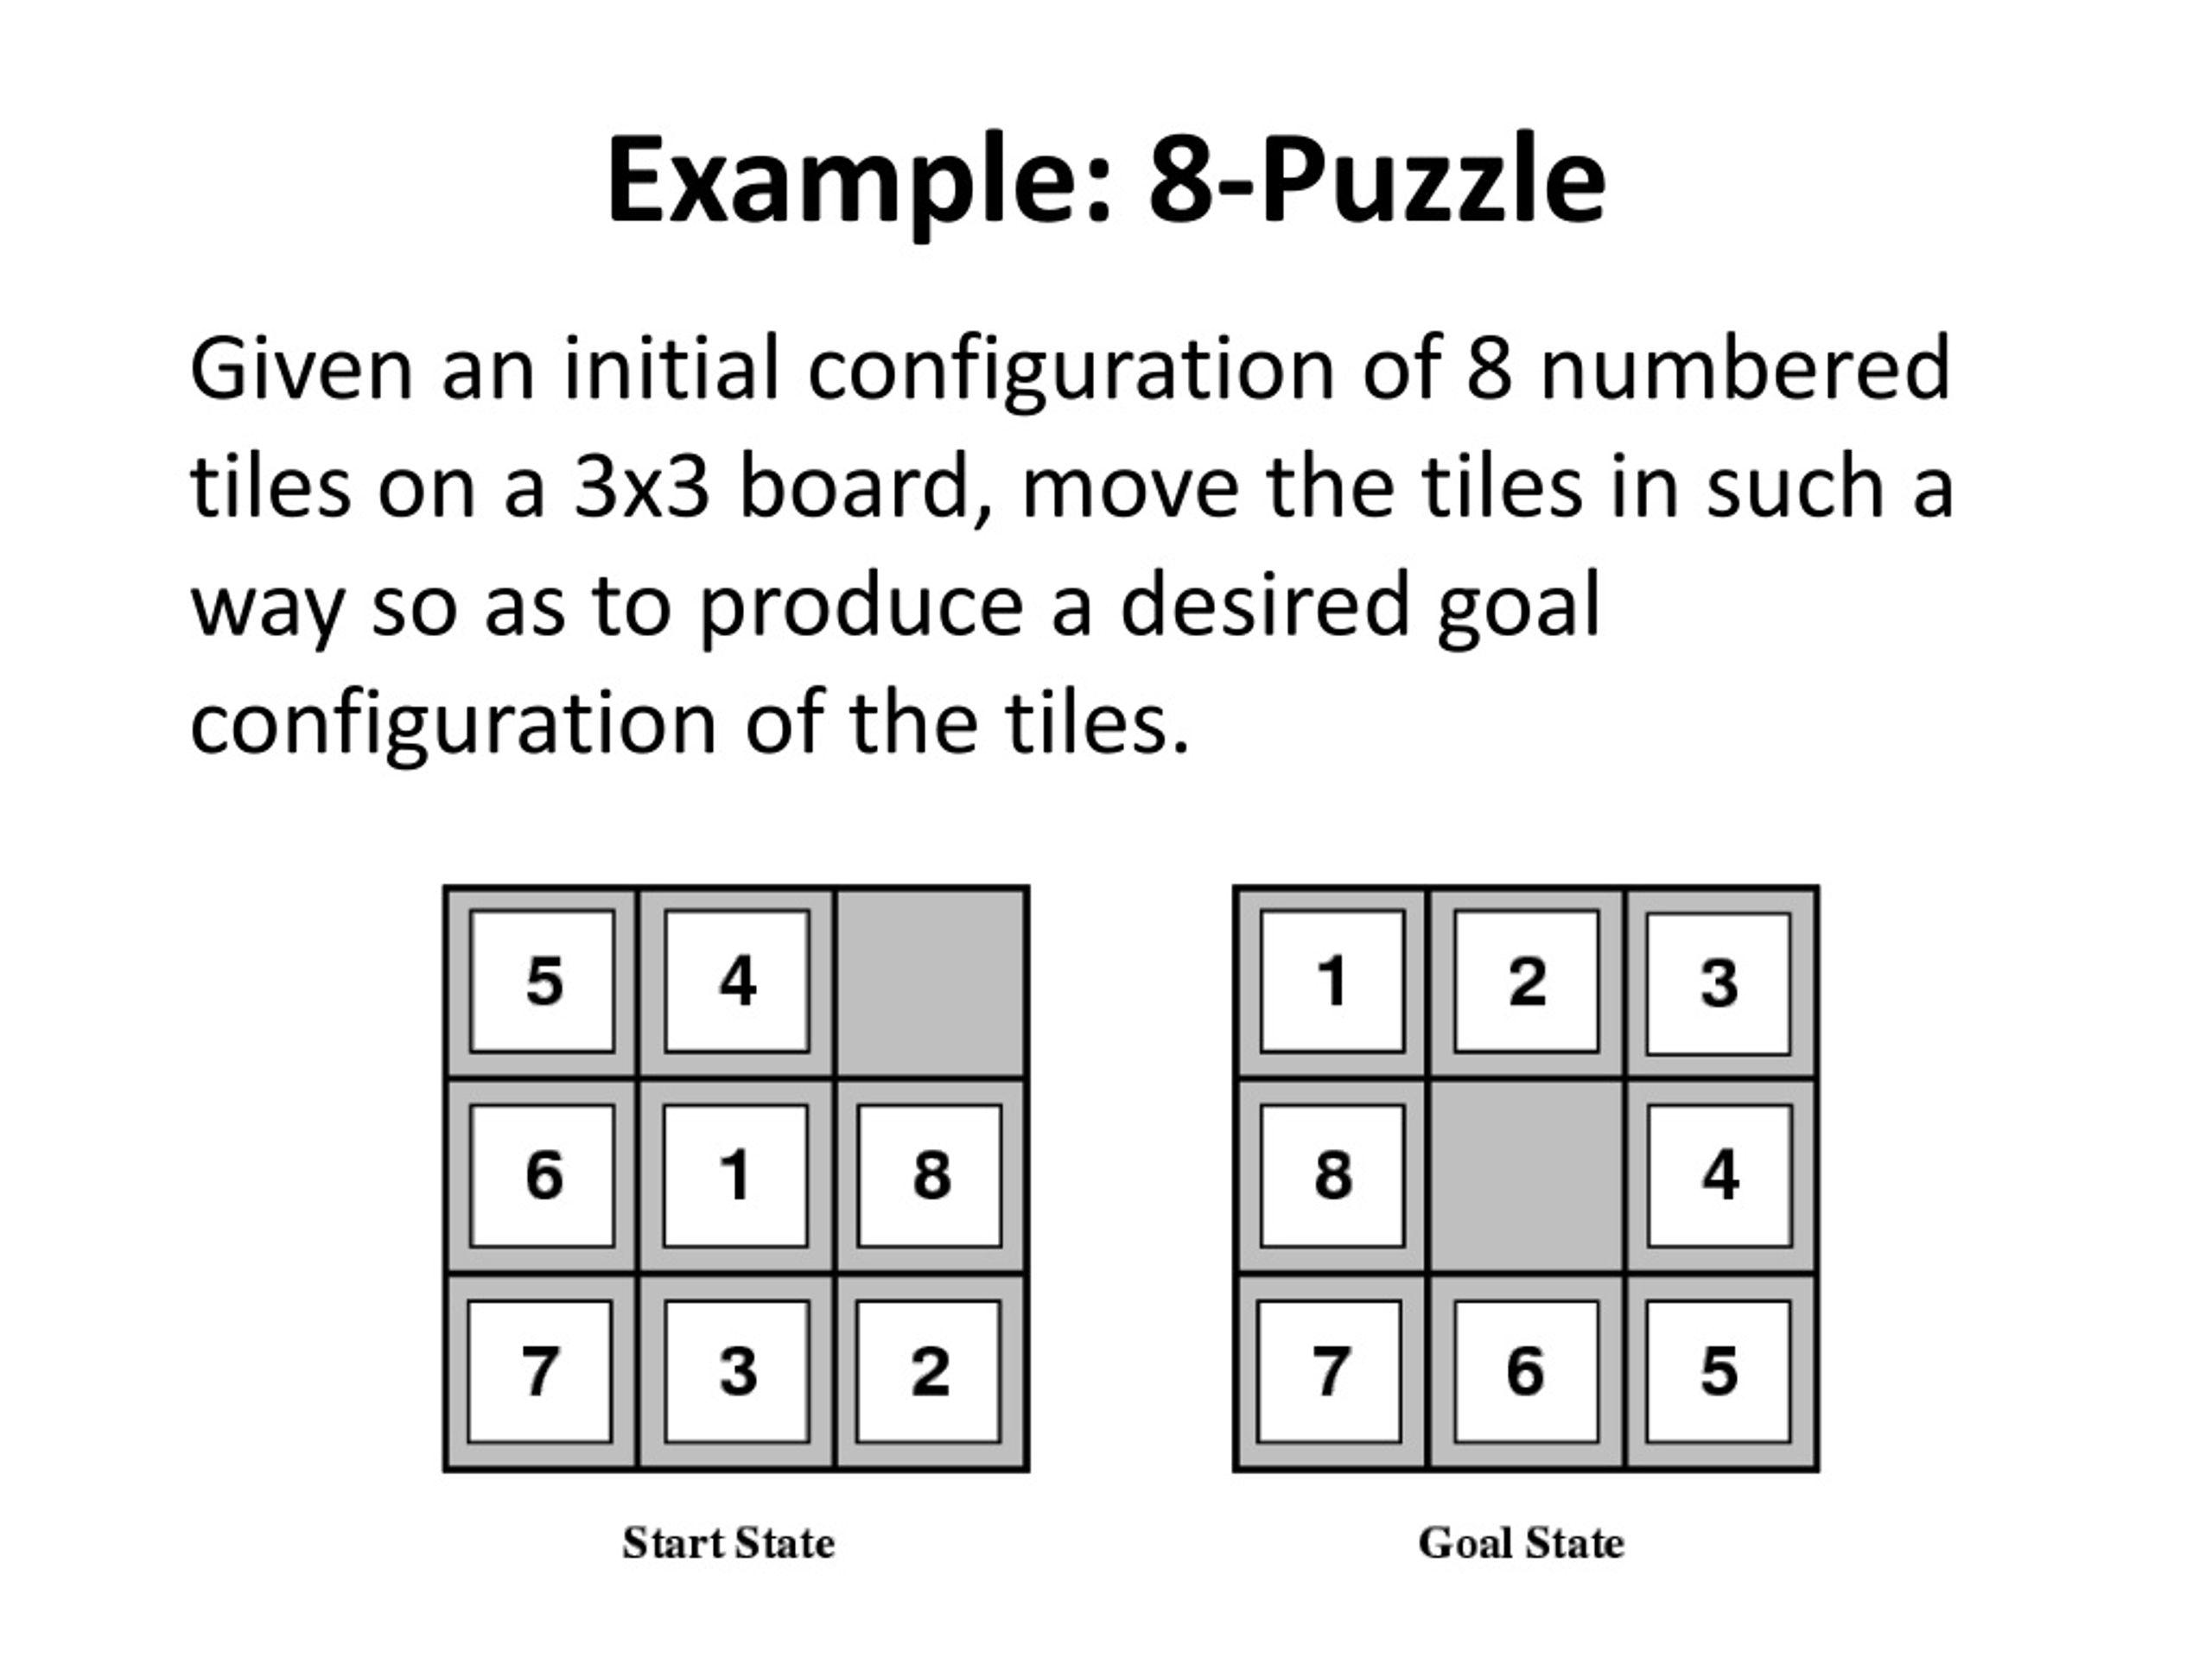

### Problem Description

- The puzzle consists of a **$3 \times 3$ grid** containing **8 numbered tiles** (from `1` to `8`) and one **empty space** (represented as `0` or blank).
- A tile adjacent to the blank space can slide horizontally or vertically into the empty space.
- Conceptually, we think of the **blank space moving** in four possible directions: **Up**, **Down**, **Left**, or **Right**.
- **Objective:** Starting from a given initial board configuration, slide tiles until the target **goal configuration** is achieved using the **minimum number of moves**.

### Learning Objectives

In this notebook, you will learn:
1. How to represent a $3 \times 3$ grid using an immutable 1D flat tuple.
2. How to map 1D indices to 2D row-column coordinates and generate valid neighboring states.
3. How to implement and apply **Breadth-First Search (BFS)** to guarantee finding the shortest path.
4. How to trace the BFS search frontier level by level.
5. The mathematics of **inversion parity** and how to determine whether an 8-puzzle configuration is solvable.

## 2. State Representation & Board Geometry

### 1D Tuple Representation

Instead of using a nested 2D list `[[...], [...], [...]]`, we represent the $3 \times 3$ board as a **flat 1D tuple** of 9 integers:

$$\text{State} = (t_0, t_1, t_2, t_3, t_4, t_5, t_6, t_7, t_8)$$

Where each index maps to a grid cell in row-major order:

| Index 0 | Index 1 | Index 2 |
|:---:|:---:|:---:|
| Index 3 | Index 4 | Index 5 |
| Index 6 | Index 7 | Index 8 |

> **Why use a tuple?**
> Tuples are **immutable** and **hashable** in Python. This allows states to be stored directly inside `visited` sets and dictionary keys with $\mathcal{O}(1)$ average lookup time.

### Index Arithmetic: Converting Between 1D and 2D

Given the index `zero` of the blank tile `0`:
- $\text{row} = \text{zero} // 3$
- $\text{col} = \text{zero} \% 3$

Given a new coordinate `(new_row, new_col)`:
- $\text{new\_zero} = \text{new\_row} \times 3 + \text{new\_col}$

### Actions (Moving the Blank Tile)

The blank tile `0` can move in up to four directions:
- **Up:** $(\Delta r = -1, \Delta c = 0)$
- **Down:** $(\Delta r = +1, \Delta c = 0)$
- **Left:** $(\Delta r = 0, \Delta c = -1)$
- **Right:** $(\Delta r = 0, \Delta c = +1)$

A move is valid if and only if $0 \le \text{new\_row} < 3$ and $0 \le \text{new\_col} < 3$.

In [17]:
def get_neighbors(state: tuple[int, ...]) -> list[tuple[int, ...]]:
    zero = state.index(0)

    row = zero // 3
    col = zero % 3

    neighbors = []

    moves = [
        (-1, 0),  # Up
        (1, 0),   # Down
        (0, -1),  # Left
        (0, 1),   # Right
    ]

    for dr, dc in moves:
        new_row = row + dr
        new_col = col + dc

        # Check if the move remains within the 3x3 board boundary
        if 0 <= new_row < 3 and 0 <= new_col < 3:
            new_zero = new_row * 3 + new_col

            new_state = list(state)

            # Swap the blank tile (0) with the adjacent tile
            new_state[zero], new_state[new_zero] = (
                new_state[new_zero],
                new_state[zero]
            )

            neighbors.append(tuple(new_state))

    return neighbors

### Branching Factor by Blank Position

The number of legal moves (branching factor) depends on where the blank tile `0` is situated on the grid:

| Blank Position | Board Locations | Number of Legal Moves | Possible Actions |
|:---|:---:|:---:|:---|
| **Corner** | Indices `0, 2, 6, 8` | **2 moves** | 2 directions along the boundary edges |
| **Edge (Middle)** | Indices `1, 3, 5, 7` | **3 moves** | 3 directions into adjacent cells |
| **Center** | Index `4` | **4 moves** | All 4 directions (Up, Down, Left, Right) |

The average branching factor across all 9 possible blank positions is:

$$b = \frac{(4 \times 2) + (4 \times 3) + (1 \times 4)}{9} = \frac{8 + 12 + 4}{9} = \frac{24}{9} \approx 2.67$$

## 3. Breadth-First Search (BFS) Implementation

### Why Breadth-First Search?

- **Unweighted Graph:** Every single tile slide incurs a step cost of $1$.
- **Shortest Path Guarantee:** BFS explores states level by level (in order of increasing path length). Therefore, the first time the goal state is discovered, the returned path is guaranteed to have the **minimum number of tile moves**.
- **Cycle Prevention:** State transitions in sliding puzzles are bidirectional (sliding a tile back immediately returns to the previous state). A `visited` set is essential to avoid infinite cycles.

### Algorithm Steps

1. Check if `start == goal`; if so, return `[start]`.
2. Initialize a FIFO queue with `deque([[start]])`.
3. Maintain a `visited` set initialized with `{start}`.
4. While the queue has paths:
   - Dequeue the oldest path: `path = queue.popleft()`.
   - Take the current board state: `state = path[-1]`.
   - For each legal neighbor from `get_neighbors(state)`:
     - If `neighbor == goal`, return `path + [neighbor]` immediately (early goal detection).
     - If `neighbor not in visited`, mark it visited and enqueue `path + [neighbor]`.
5. If the queue becomes empty without reaching the goal, return `None` (unsolvable).

In [18]:
from collections import deque

def bfs(start: tuple[int, ...], goal: tuple[int, ...]) -> list[tuple[int, ...]] | None:
    if start == goal:
        return [start]

    queue = deque([[start]])
    visited = {start}

    while queue:
        path = queue.popleft()
        state = path[-1]

        for neighbor in get_neighbors(state):
            if neighbor == goal:
                return path + [neighbor]

            if neighbor not in visited:
                visited.add(neighbor)
                queue.append(path + [neighbor])

    return None

## 4. Running BFS on the Example Puzzle

Let's define the initial configuration and the standard goal configuration:

$$\text{Start} = \begin{bmatrix} 1 & 2 & 3 \\ 4 & \mathbf{0} & 6 \\ 7 & 5 & 8 \end{bmatrix}, \quad \text{Goal} = \begin{bmatrix} 1 & 2 & 3 \\ 4 & 5 & 6 \\ 7 & 8 & \mathbf{0} \end{bmatrix}$$

We execute BFS and print each intermediate step along with the move direction and the tile slid.

In [20]:
start = (1, 2, 3,
         4, 0, 6,
         7, 5, 8)

goal = (1, 2, 3,
        4, 5, 6,
        7, 8, 0)

path = bfs(start, goal)

if path:
    for step, state in enumerate(path):
        print(f"Step {step}")

        for i in range(0, 9, 3):
            print(state[i:i + 3])

        print()
else:
    print("No solution found.")

Step 0
(1, 2, 3)
(4, 0, 6)
(7, 5, 8)

Step 1
(1, 2, 3)
(4, 5, 6)
(7, 0, 8)

Step 2
(1, 2, 3)
(4, 5, 6)
(7, 8, 0)



## 5. Step-by-Step Execution & Tracing

Let's trace how BFS explores the state space from `start` to `goal`.

### 5.1 BFS Search Frontier Trace

The table below shows the exact state of the FIFO `queue` and `visited` set at each iteration of the search loop:

| Step | Popped State (`state`) | Path Depth | Action Taken | Newly Discovered Neighbors | Queue Size | Search Status |
|:---:|:---|:---:|:---:|:---|:---:|:---|
| **Initial** | — | — | — | `(1, 2, 3, 4, 0, 6, 7, 5, 8)` | 1 | Start state enqueued and added to `visited` |
| **1** | `(1, 2, 3, 4, 0, 6, 7, 5, 8)` | 0 | Blank at center (4) | `(1, 0, 3, 4, 2, 6, 7, 5, 8)` [Up]<br>`(1, 2, 3, 4, 5, 6, 7, 0, 8)` [Down]<br>`(1, 2, 3, 0, 4, 6, 7, 5, 8)` [Left]<br>`(1, 2, 3, 4, 6, 0, 7, 5, 8)` [Right] | 4 | All 4 center moves discovered; 4 paths added to queue |
| **2** | `(1, 0, 3, 4, 2, 6, 7, 5, 8)` | 1 | Up from center | `(0, 1, 3, 4, 2, 6, 7, 5, 8)` [Left]<br>`(1, 3, 0, 4, 2, 6, 7, 5, 8)` [Right] | 5 | Down leads back to visited start; 2 new states enqueued |
| **3** | `(1, 2, 3, 4, 5, 6, 7, 0, 8)` | 1 | Down from center | `(1, 2, 3, 4, 5, 6, 0, 7, 8)` [Left]<br>**`(1, 2, 3, 4, 5, 6, 7, 8, 0)` [Right - GOAL!]** | 4 | **Goal found! Path returned immediately.** |

---

### 5.2 Physical Solution Path Trace

Here is the visual board layout at each step of the solution:

| Step | Action | Board Layout | Description |
|:---:|:---|:---:|:---|
| **0** | *Initial State* | $\begin{matrix} 1 & 2 & 3 \\ 4 & \mathbf{0} & 6 \\ 7 & 5 & 8 \end{matrix}$ | Blank `0` is at index 4 (center). Tiles 5 and 8 are out of goal positions. |
| **1** | **Move Blank Down**<br>*(Slide tile 5 Up)* | $\begin{matrix} 1 & 2 & 3 \\ 4 & 5 & 6 \\ 7 & \mathbf{0} & 8 \end{matrix}$ | Tile 5 slides into row 1, col 1, locking into its goal position. Blank moves to bottom row. |
| **2** | **Move Blank Right**<br>*(Slide tile 8 Left)* | $\begin{matrix} 1 & 2 & 3 \\ 4 & 5 & 6 \\ 7 & 8 & \mathbf{0} \end{matrix}$ | Tile 8 slides into bottom middle, locking into its goal position. Blank reaches bottom-right. **Goal achieved!** |

## 6. Complexity Analysis

### State Space Characteristics

- **Total Configurations:** $9! = 362,880$.
- **Reachable States:** Exactly half, $\frac{9!}{2} = 181,440$ states.
- **Average Branching Factor ($b$):** $\approx 2.67$.
- **God's Number for 8-Puzzle:** The maximum optimal solution depth from any solvable state is **31 moves**.

### Time Complexity

- In the worst case, BFS explores states level by level up to depth $d$:
  $$\text{Time Complexity} = \mathcal{O}(b^d)$$
- For shallow depths (such as $d = 2$ in our example), BFS visits only 8 states and finishes instantaneously ($< 1$ ms).
- For difficult instances near depth $d = 31$, the search space grows exponentially, requiring tens of thousands of state expansions.

### Space Complexity

- BFS must store all generated paths in the queue and all discovered states in the `visited` set:
  $$\text{Space Complexity} = \mathcal{O}(b^d)$$
- Auxiliary memory can become a bottleneck for larger puzzle dimensions (e.g., 15-Puzzle with $16! / 2 \approx 1.04 \times 10^{13}$ states).

### Transition to Heuristic Search

Because uninformed BFS explores blindly in all directions without knowing which direction gets closer to the goal, AI systems use **Informed Search Algorithms** such as **$A^*$ Search** with heuristics:
1. **Misplaced Tiles ($h_1$):** Count of tiles not in their goal position.
2. **Manhattan Distance ($h_2$):** Sum of horizontal and vertical distances of tiles from their target positions.